# Ajuste no lineal — oscilaciones amortiguadas
**Objetivo:** ajustar una función no lineal con `curve_fit` y comparar con la formulación mediante residuos `leastsq`, siguiendo la clase.

## 1. Leer datos y proponer modelo
Se prueba el modelo de clase $f(x)=a+e^{-bx}\sin(cx)$. No todos los parámetros aparecen linealmente.

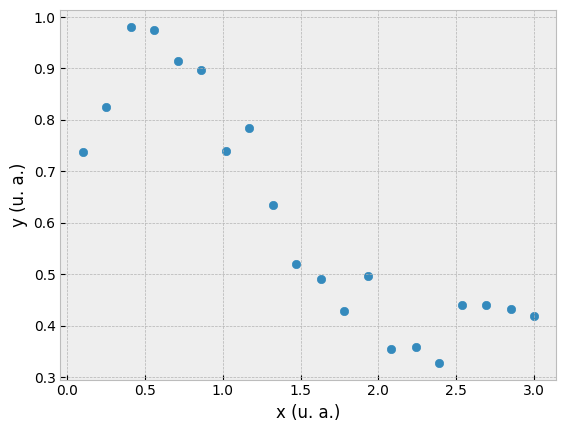

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit, leastsq
plt.style.use('bmh')

x, y = np.genfromtxt('ej-ajuste-03.txt').T

def f(x, a, b, c):
    return a + np.exp(-b*x)*np.sin(c*x)

plt.scatter(x, y)
plt.xlabel('x (u. a.)'); plt.ylabel('y (u. a.)')
plt.show()

## 2. `curve_fit`: parámetros optimizados
`curve_fit` devuelve un vector de parámetros y una matriz de covarianzas estimada. Aquí solo comparamos valores ajustados.

Parámetros [a,b,c]: [0.48092 1.02623 1.91603]


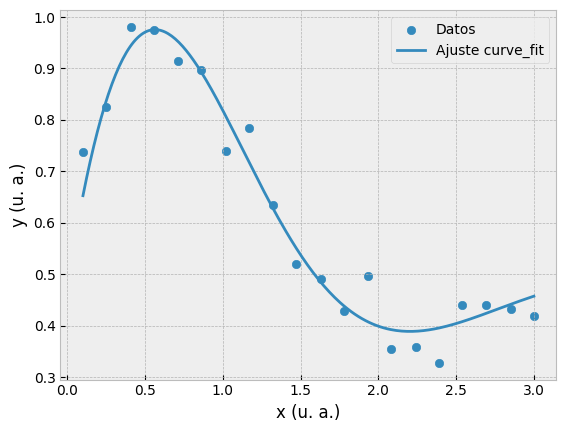

In [2]:
p0 = [0.5, 1.2, 1.9]
param, cov = curve_fit(f, x, y, p0=p0, maxfev=10000)
print('Parámetros [a,b,c]:', np.round(param, 5))
xx = np.linspace(x.min(), x.max(), 250)
plt.scatter(x, y, label='Datos')
plt.plot(xx, f(xx, *param), label='Ajuste curve_fit')
plt.xlabel('x (u. a.)');plt.ylabel('y (u. a.)');plt.legend();plt.show()

## 3. `leastsq`: ajustar residuos
La función que minimizamos es $r_i=y_i-f(x_i;\mathbf p)$, no el modelo por sí solo.

In [3]:
def residuos(p, x, y):
    return y - f(x, *p)

param2, _ = leastsq(residuos, p0, args=(x, y))
print('curve_fit:', np.round(param, 5))
print('leastsq:  ', np.round(param2, 5))
print('Suma de residuos²:', np.sum(residuos(param2, x, y)**2))

curve_fit: [0.48092 1.02623 1.91603]
leastsq:   [0.48092 1.02623 1.91603]
Suma de residuos²: 0.03819275173743989


## 4. Segundo ejemplo de clase — curva con forma de campana

El notebook original explora una potencia $a+(x+b)^{-c}$ y una curva $1/\cosh x$. La potencia no queda definida como real en todo este conjunto sin restricciones. Usaremos la **forma de campana** para practicar `curve_fit`, sin atribuirle significado físico adicional.

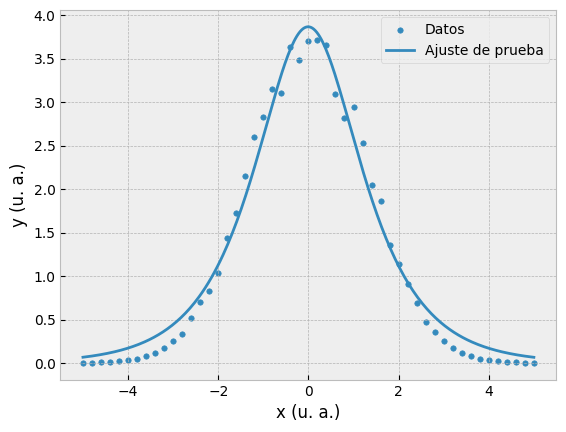

Parámetros (A, centro, ancho): [ 3.869 -0.006  1.048]


In [4]:
v, u = np.genfromtxt('ejemplo-s10.txt').T

def campana(x, A, centro, ancho):
    return A / np.cosh((x - centro) / ancho)

param_campana, _ = curve_fit(campana, v, u, p0=[3.7, 0, 1.2])
x_denso = np.linspace(v.min(), v.max(), 300)
plt.scatter(v, u, s=15, label='Datos')
plt.plot(x_denso, campana(x_denso, *param_campana), label='Ajuste de prueba')
plt.xlabel('x (u. a.)');plt.ylabel('y (u. a.)');plt.legend();plt.show()
print('Parámetros (A, centro, ancho):', np.round(param_campana, 3))

**Comprueba:** ¿por qué necesita `leastsq` una función de residuos? ¿Qué forma funcional propondrías para el segundo ejemplo sin perder el dominio real?